# Layout to Outline Converter

Converts layout images into black-and-white outline images by mapping all non-black colors and backgrounds to white.

In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
current_dir = Path.cwd()
if (current_dir / "data").exists():
    ROOT = current_dir
elif (current_dir.parent / "data").exists():
    ROOT = current_dir.parent
else:
    ROOT = Path(".")

DATA_DIR = ROOT / "data"

PLAN = "plan1"
IMAGE_PATH = DATA_DIR / PLAN / "layout.png"

BLACK_THRESHOLD = 120
SATURATION_THRESHOLD = 30

## Outline conversion function

Pixels with intensity below BLACK_THRESHOLD and chromatic spread below SATURATION_THRESHOLD remain black. All other pixels (colors and backgrounds) become white.

In [3]:
def convert_layout_to_outline(
    image_bgr: np.ndarray,
    threshold: int = 120,
    sat_thresh: int = 30,
) -> np.ndarray:
    rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    c_max = np.max(rgb, axis=2).astype(np.int32)
    c_min = np.min(rgb, axis=2).astype(np.int32)
    saturation = c_max - c_min

    is_black = (gray < threshold) & (saturation < sat_thresh)

    outline = np.full(image_bgr.shape[:2], 255, dtype=np.uint8)
    outline[is_black] = 0
    return outline

In [4]:
image = cv2.imread(str(IMAGE_PATH))
if image is None:
    raise FileNotFoundError(f"Image not found at {IMAGE_PATH}")

outline = convert_layout_to_outline(
    image,
    threshold=BLACK_THRESHOLD,
    sat_thresh=SATURATION_THRESHOLD,
)

print(f"Loaded: {IMAGE_PATH} ({image.shape[1]}x{image.shape[0]})")
print(f"Black pixels: {np.mean(outline == 0) * 100:.2f}%")
print(f"White pixels: {np.mean(outline == 255) * 100:.2f}%")

Loaded: /Users/arya/Projects/ADA/bazaar/floor-plan-extractor/legend-only/data/plan1/layout.png (2349x2871)
Black pixels: 3.66%
White pixels: 96.34%


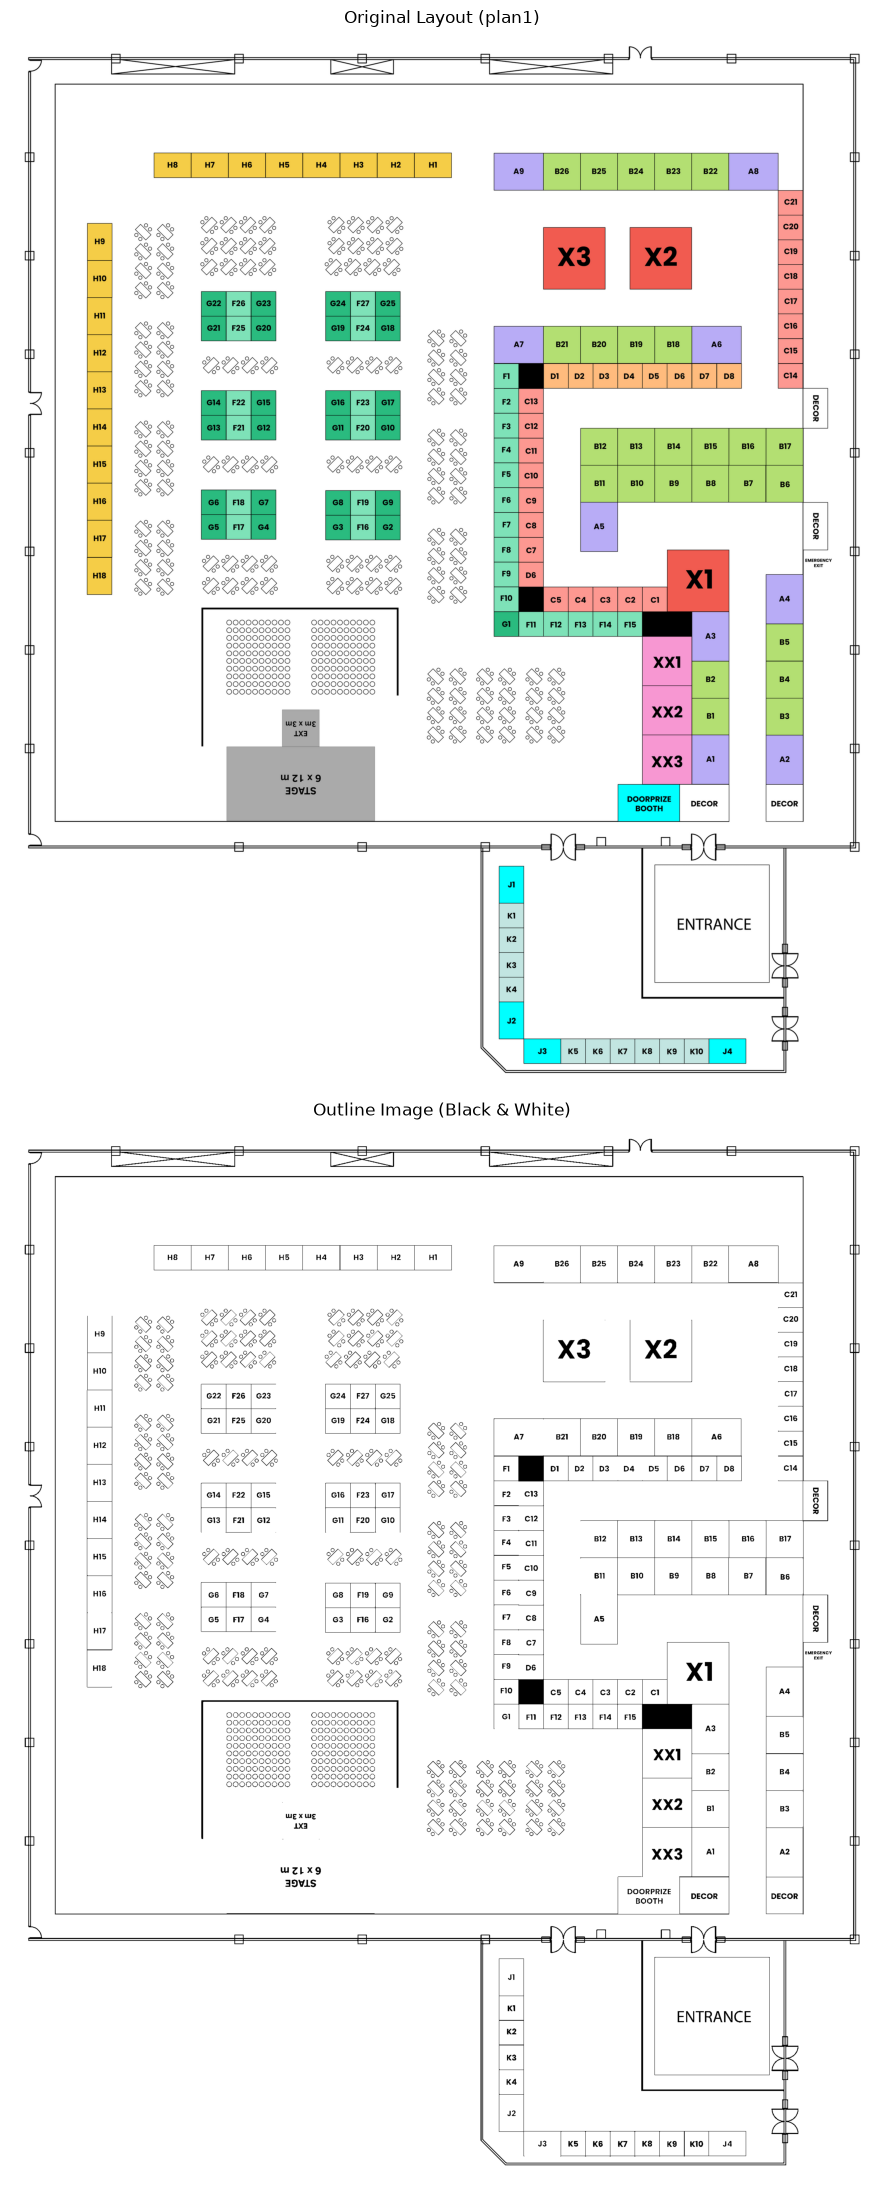

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 22))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Original Layout ({PLAN})")
axes[0].axis("off")

axes[1].imshow(outline, cmap="gray")
axes[1].set_title("Outline Image (Black & White)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

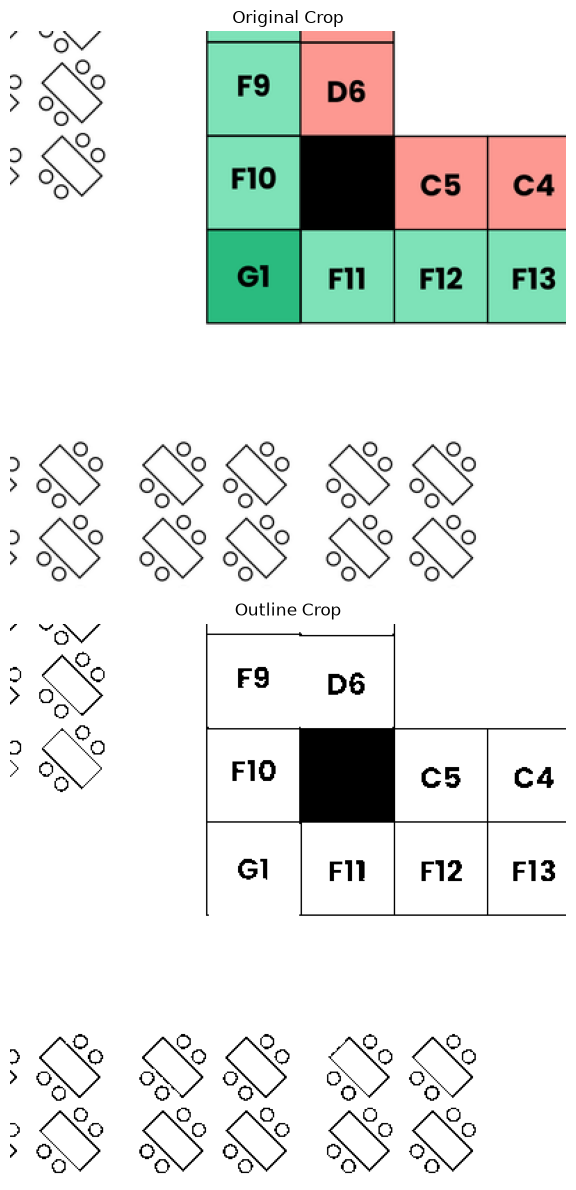

In [6]:
h, w = image.shape[:2]
crop_size = min(400, h, w)
cy, cx = h // 2, w // 2

orig_crop = cv2.cvtColor(image[cy : cy + crop_size, cx : cx + crop_size], cv2.COLOR_BGR2RGB)
outline_crop = outline[cy : cy + crop_size, cx : cx + crop_size]

fig, axes = plt.subplots(2, 1, figsize=(8, 12))
axes[0].imshow(orig_crop)
axes[0].set_title("Original Crop")
axes[0].axis("off")

axes[1].imshow(outline_crop, cmap="gray")
axes[1].set_title("Outline Crop")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Extract and remove text

Extracts text regions using EasyOCR and clears them from the outline image by filling text polygons with white.

Extracted 164 text regions
Sample text: ['H8', 'H7', 'H6', 'H5', 'H4', 'H3', 'H2', 'HI', 'A9', 'B26']


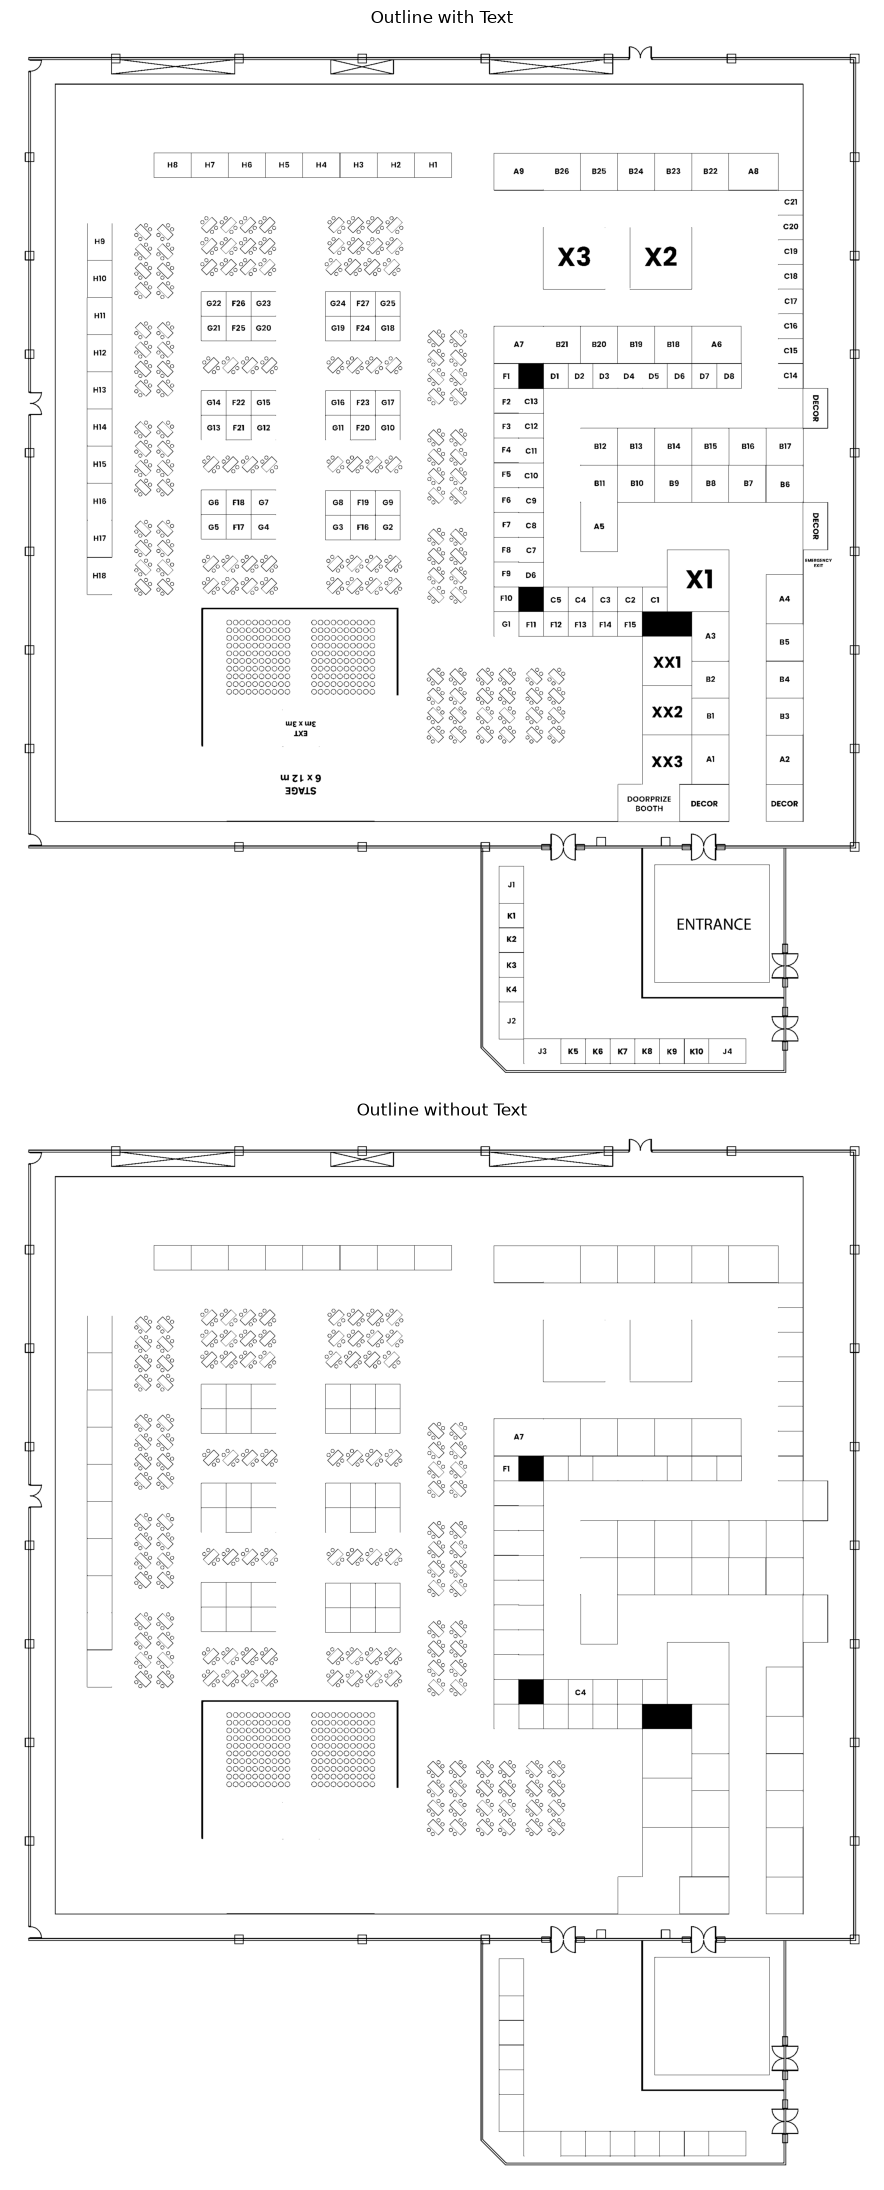

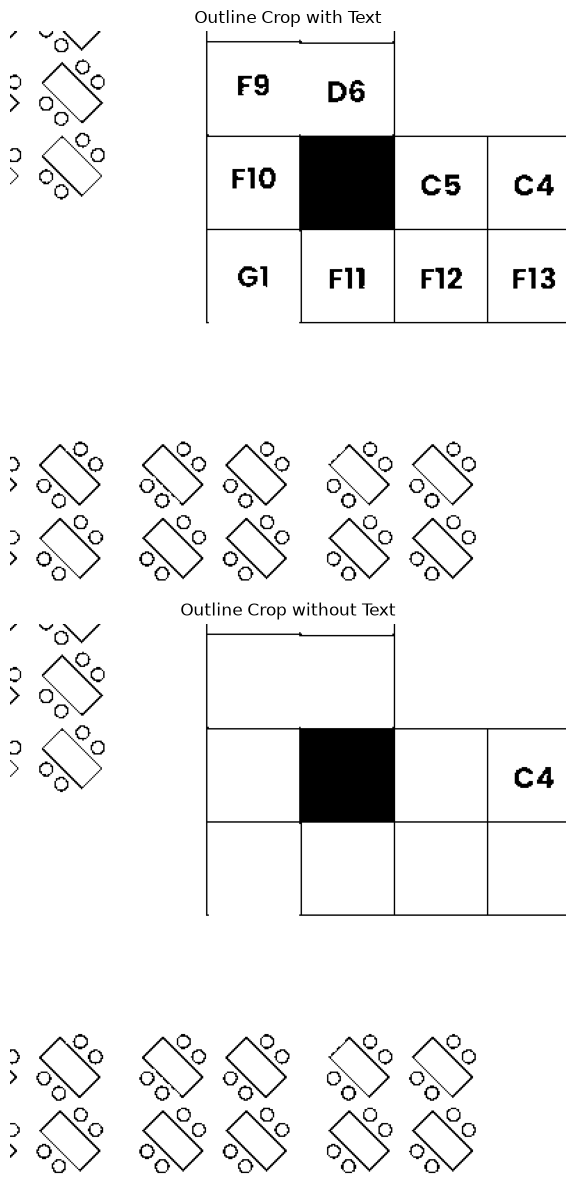

In [7]:
import warnings
import easyocr

warnings.filterwarnings("ignore")

reader = easyocr.Reader(["en"], gpu=False, verbose=False)
text_detections = reader.readtext(image)

outline_no_text = outline.copy()
for bbox, text, conf in text_detections:
    pts = np.array(bbox, dtype=np.int32)
    cv2.fillPoly(outline_no_text, [pts], 255)

print(f"Extracted {len(text_detections)} text regions")
print(f"Sample text: {[t[1] for t in text_detections[:10]]}")

fig, axes = plt.subplots(2, 1, figsize=(12, 22))
axes[0].imshow(outline, cmap="gray")
axes[0].set_title("Outline with Text")
axes[0].axis("off")

axes[1].imshow(outline_no_text, cmap="gray")
axes[1].set_title("Outline without Text")
axes[1].axis("off")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(8, 12))
axes[0].imshow(outline[cy : cy + crop_size, cx : cx + crop_size], cmap="gray")
axes[0].set_title("Outline Crop with Text")
axes[0].axis("off")

axes[1].imshow(outline_no_text[cy : cy + crop_size, cx : cx + crop_size], cmap="gray")
axes[1].set_title("Outline Crop without Text")
axes[1].axis("off")

plt.tight_layout()
plt.show()